**Bank Marketing Campaign Prediction**

## Background
A Portuguese banking institution conducted direct marketing campaigns through telephone calls to promote term deposit subscriptions. The campaign generated customer-level data containing demographic characteristics, financial information, previous campaign interactions, and macroeconomic indicators. The outcome variable (y) indicates whether a customer subscribed to a term deposit following the marketing contact

## Objective
The objective of this project is to develop and evaluate machine learning models capable of predicting whether a customer will subscribe to a term deposit. Accurate predictions can help the bank identify customers with the highest likelihood of subscribing and prioritize them for future marketing campaigns. This can improve campaign efficiency, reduce unnecessary contact costs, and increase the overall return on marketing investment

## Business Problem
Telephone marketing campaigns are costly because they require staff time and communication resources. Contacting every customer may result in a large number of unsuccessful calls. A predictive model can support decision-making by estimating the probability of subscription for each customer, enabling the bank to focus resources on customers who are more likely to respond positively

## Analytical Objectives
Explore and understand the structure, characteristics, and limitations of the dataset.

Prepare the data for predictive modelling using appropriate preprocessing techniques.

Establish a majority-class baseline model for comparison.

Develop and evaluate up to three classification models for predicting term-deposit subscription.

Compare model performance using appropriate evaluation metrics.

Recommend an operational decision threshold that balances the trade-off between unnecessary marketing calls and missed subscription opportunities

*Question 1*

#Data Loading and Initial Inspection

In [4]:
from google.colab import files

uploaded = files.upload()

Saving bank-additional-full.csv to bank-additional-full.csv


In [5]:
import pandas as pd

df = pd.read_csv('bank-additional-full.csv', sep=';')

df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


*Inspecting the data *

In [6]:
# Dataset dimensions
print("Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Info:")
df.info()


Shape: (41188, 21)

Columns:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign    

Dataset Overview

The dataset contains 41,188 customer records and 21 variables collected during direct marketing campaigns conducted by a Portuguese banking institution. The objective is to predict whether a customer will subscribe to a term deposit, represented by the target variable y.

The dataset consists of a mix of demographic, financial, campaign-related, and macroeconomic variables. The features include customer characteristics such as age, occupation, marital status, and education level, as well as information about previous marketing contacts and broader economic conditions.

A review of the data structure shows that all 41,188 observations contain values for every variable, indicating that there are no conventional missing values (null values) in the dataset.

The dataset contains:

41,188 observations

21 variables

10 numerical variables (5 integer and 5 continuous)

11 categorical variables


1 binary target variable (y)

The absence of null values reduces the need for traditional missing-value imputation. However, further investigation is required to determine whether some categorical variables contain placeholder values such as "unknown" that may represent missing information.

*DATA QUALITY ASSESSMENT*

In [7]:
# 1. Dataset shape
print("Dataset Shape:", df.shape)

# 2. Duplicate records
duplicates = df.duplicated().sum()
print("\nNumber of duplicate records:", duplicates)

# 3. Missing values
print("\nMissing Values per Variable:")
print(df.isnull().sum())

# 4. Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# 5. Check for 'unknown' values in categorical variables
print("\nNumber of 'unknown' values per categorical variable:\n")

categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    unknown_count = (df[col] == 'unknown').sum()
    print(f"{col}: {unknown_count}")

Dataset Shape: (41188, 21)

Number of duplicate records: 12

Missing Values per Variable:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Total Missing Values: 0

Number of 'unknown' values per categorical variable:

job: 330
marital: 80
education: 1731
default: 8597
housing: 990
loan: 990
contact: 0
month: 0
day_of_week: 0
poutcome: 0
y: 0


A data quality assessment was conducted to identify duplicate records, missing values, and placeholder categories.

The dataset contained 12 duplicate observations, representing approximately 0.03% of all records. These duplicate records will be removed to avoid potential bias during model training and evaluation.

No conventional missing values were identified in any variable. Therefore, no missing-value imputation is required.

Although no null values were present, several categorical variables contained the category "unknown". The highest occurrence was observed in the variable default, where approximately 20.9% of observations were recorded as unknown. Rather than removing these observations or replacing the values, the "unknown" category will be retained because it may contain predictive information and represents a meaningful customer characteristic.

Overall, the dataset demonstrates a high level of completeness and requires only minimal cleaning before further analysis.

Removing Duplicates

Duplicate records can give certain observations more influence during model training and introduce bias in performance evaluation. Since the number of duplicates is very small, removing them improves data quality without materially affecting the dataset.

In [8]:
# Remove duplicate records
df = df.drop_duplicates()

# Verify new shape
print("New Dataset Shape:", df.shape)

# Check duplicates again
print("Remaining Duplicates:", df.duplicated().sum())

New Dataset Shape: (41176, 21)
Remaining Duplicates: 0


Original Shape : (41188, 21)

Duplicates Removed : 12

Current Shape : (41176, 21)

Remaining Duplicates : 0

*Checking for unique values in categorical variables*

In [9]:
categorical_columns = df.select_dtypes(
    include='object'
).columns

for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts().head(10))


 job
job
admin.           10419
blue-collar       9253
technician        6739
services          3967
management        2924
retired           1718
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
Name: count, dtype: int64

 marital
marital
married     24921
single      11564
divorced     4611
unknown        80
Name: count, dtype: int64

 education
education
university.degree      12164
high.school             9512
basic.9y                6045
professional.course     5240
basic.4y                4176
basic.6y                2291
unknown                 1730
illiterate                18
Name: count, dtype: int64

 default
default
no         32577
unknown     8596
yes            3
Name: count, dtype: int64

 housing
housing
yes        21571
no         18615
unknown      990
Name: count, dtype: int64

 loan
loan
no         33938
yes         6248
unknown      990
Name: count, dtype: int64

 contact
contact
cellular     26135
telephone    15041
Nam

The categorical variables were examined to understand customer characteristics and identify potential data quality concerns. Most customers were employed in administrative, blue-collar, and technical occupations. The majority were married and had either a university degree or high-school education.

Several variables contained an "unknown" category, most notably the variable default, where approximately 20.9% of observations had an unknown value. These records were retained because unknown responses may contain predictive information.

The variable poutcome indicates that most customers had not participated in a previous campaign, while only a small proportion experienced a successful prior contact. As previous campaign outcomes may influence future customer behaviour, this variable is expected to be important in prediction models.

The target variable y is highly imbalanced, with approximately 88.7% of customers not subscribing to a term deposit and only 11.3% subscribing. Consequently, accuracy alone is not an appropriate performance metric, and additional metrics such as Precision, Recall, F1-score, and ROC-AUC will be used to evaluate model performance.

**Target Variable Analysis**

*Class Distribution Analysis*

In [10]:
# Percentage distribution of the target variable

target_pct = round(df['y'].value_counts(normalize=True) * 100, 2)

print(target_pct)

y
no     88.73
yes    11.27
Name: proportion, dtype: float64


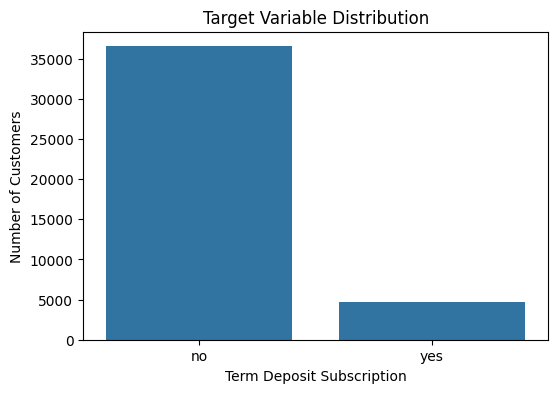

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))

sns.countplot(x='y', data=df)

plt.title('Target Variable Distribution')
plt.xlabel('Term Deposit Subscription')
plt.ylabel('Number of Customers')

plt.show()


The target variable (y) represents whether a customer subscribed to a term deposit following a marketing campaign.

Analysis of the class distribution revealed that 88.73% of customers did not subscribe to a term deposit, while only 11.27% subscribed. The distribution is therefore highly imbalanced, with the majority class substantially outnumbering the minority class.

This imbalance has important implications for predictive modelling. A model that predicts every customer as a non-subscriber would achieve an accuracy of approximately 88.73%, despite having no ability to identify actual subscribers. Consequently, accuracy alone is not an appropriate evaluation metric for this problem.

To provide a more reliable assessment of model performance, additional metrics including Precision, Recall, F1-Score, and ROC-AUC will be used. A majority-class baseline model will also be established to ensure that all predictive models demonstrate meaningful improvement over a naïve classification strategy.

*Target Variable Distribution*

In [12]:
# Identify numerical and categorical variables

numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numerical Variables:")
print(numerical_cols)

print("\nCategorical Variables:")
print(categorical_cols)

Numerical Variables:
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical Variables:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']


To guide the exploratory data analysis and preprocessing stages, the variables were classified according to their data type.

The dataset contains 10 numerical predictor variables and 10 categorical predictor variables, in addition to the binary target variable (y). The numerical variables consist of customer characteristics, campaign information, and macroeconomic indicators, while the categorical variables describe customer demographics, financial status, contact methods, and previous campaign outcomes.

The presence of both numerical and categorical predictors suggests that appropriate preprocessing techniques will be required before model development. In particular, categorical variables will need to be encoded into numerical representations suitable for machine learning algorithms.

**Exploratory Data Analysis**

*Numerical Variable Analysis*

In [13]:
# Summary statistics for numerical variables

df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.023800,10.420680,17.000,32.000,38.000,47.000,98.000
duration,41176.0,258.315815,259.305321,0.000,102.000,180.000,319.000,4918.000
campaign,41176.0,2.567879,2.770318,1.000,1.000,2.000,3.000,56.000
pdays,41176.0,962.464810,186.937102,0.000,999.000,999.000,999.000,999.000
previous,41176.0,0.173013,0.494964,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41176.0,0.081922,1.570883,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41176.0,93.575720,0.578839,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41176.0,-40.502863,4.627860,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41176.0,3.621293,1.734437,0.634,1.344,4.857,4.961,5.045
nr.employed,41176.0,5167.034870,72.251364,4963.600,5099.100,5191.000,5228.100,5228.100


Summary statistics were computed for all numerical variables to understand their central tendency, dispersion, and potential data quality issues.

Customer age ranges from 17 to 98 years, with an average age of approximately 40 years. Several variables, particularly duration and campaign, exhibit large differences between their mean and median values, suggesting the presence of right-skewed distributions and potential outliers.

The variable duration shows substantial variability, with call durations ranging from 0 to 4,918 seconds. This variable is expected to be highly predictive but may introduce data leakage because call duration is only known after the call has been completed.

The variable pdays contains a large number of observations coded as 999, which represents customers who were not previously contacted. Consequently, this variable requires careful interpretation during data preparation.

The macroeconomic indicators (emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, and nr.employed) demonstrate noticeable variation and may provide additional predictive value regarding customer subscription behaviour.

*Distribution of Numerical Variables*

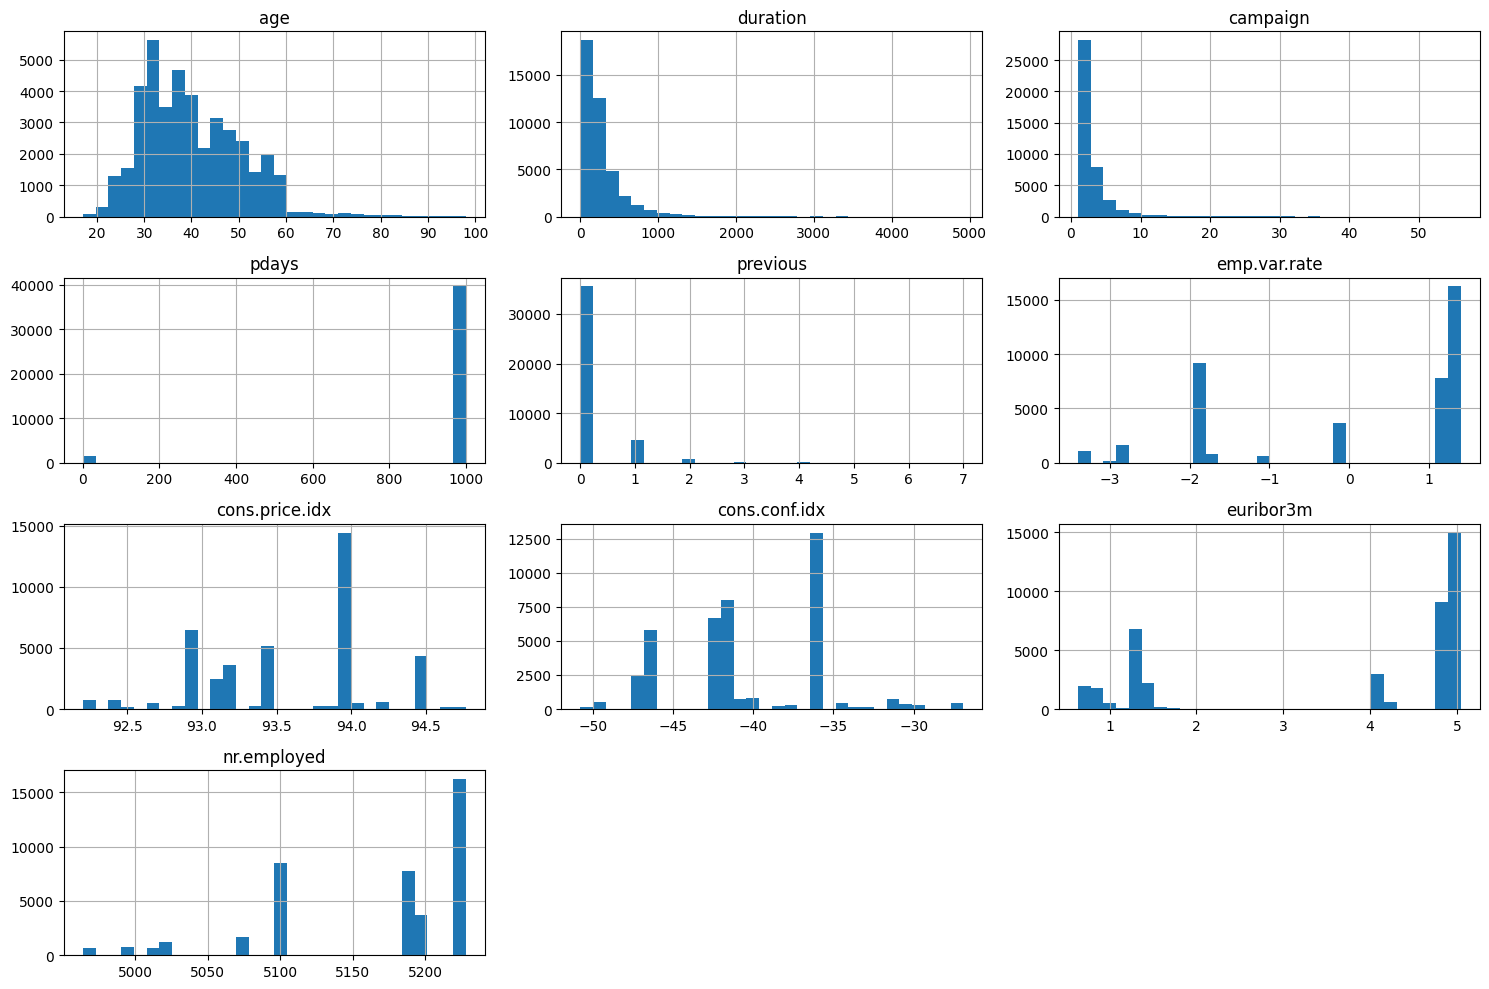

In [14]:
# Histograms for numerical variables

df[numerical_cols].hist(
    figsize=(15,10),
    bins=30
)

plt.tight_layout()
plt.show()

istograms were used to examine the distribution of numerical variables and identify potential issues such as skewness, outliers, and unusual coding patterns.

The variables duration, campaign, and previous exhibit strong right-skewed distributions, with most observations concentrated at lower values and a small number of extreme observations. This suggests the presence of potential outliers that may influence model training.

The variable age appears reasonably distributed, although a small number of customers are substantially older than the majority of the population.

The variable pdays shows a highly unusual distribution, with most observations taking the value 999. According to the dataset documentation, this value indicates that the customer was not previously contacted. Consequently, this variable should not be interpreted as a standard continuous variable.

The macroeconomic indicators (emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, and nr.employed) appear to follow clustered distributions, reflecting different economic conditions during the campaign period.

A particularly important observation concerns the variable duration, which represents the duration of the marketing call. While this variable is expected to be highly predictive, it is only known after a call has been completed and may therefore introduce data leakage in predictive modelling.

*Skewness Analysis of Numerical Variables*

In [15]:
# Measure skewness of numerical variables

skewness = df[numerical_cols].skew().sort_values(ascending=False)

print(skewness)

campaign          4.762044
previous          3.831396
duration          3.262808
age               0.784560
cons.conf.idx     0.302876
cons.price.idx   -0.230853
euribor3m        -0.709194
emp.var.rate     -0.724061
nr.employed      -1.044317
pdays            -4.921386
dtype: float64


Skewness statistics were calculated to assess the symmetry of the numerical variables and identify potential departures from normality.

The variables campaign (4.76), previous (3.83), and duration (3.26) exhibit strong positive skewness, indicating that most observations occur at low values while a small number of customers experienced unusually large values. This pattern is consistent with the histograms and suggests the presence of outliers.

The variable age shows moderate positive skewness (0.78), reflecting a longer tail towards older customers.

The most extreme negative skewness was observed for pdays (-4.92), which is largely explained by the dominance of the value 999, representing customers who had not been previously contacted. Consequently, this variable should not be interpreted as a typical continuous variable.

Overall, several numerical variables are noticeably skewed; however, these patterns appear to reflect genuine characteristics of the marketing campaign rather than data quality errors.

*Outlier Analysis of Numerical Variables*

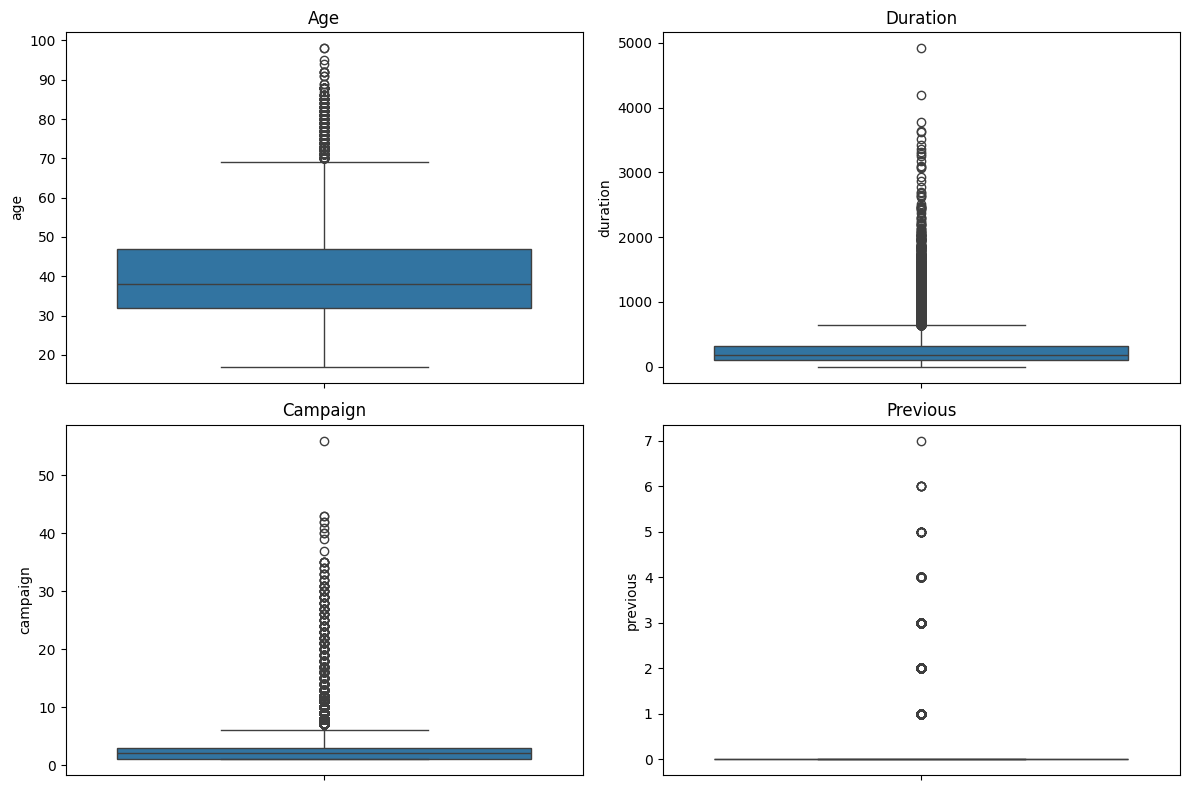

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(12,8))

sns.boxplot(y=df['age'], ax=axes[0,0])
axes[0,0].set_title('Age')

sns.boxplot(y=df['duration'], ax=axes[0,1])
axes[0,1].set_title('Duration')

sns.boxplot(y=df['campaign'], ax=axes[1,0])
axes[1,0].set_title('Campaign')

sns.boxplot(y=df['previous'], ax=axes[1,1])
axes[1,1].set_title('Previous')

plt.tight_layout()
plt.show()

Boxplots were used to identify potential outliers within the numerical variables.

Several variables, including age, duration, campaign, and previous, contain observations that fall outside the interquartile range. The most notable outliers occur in duration and campaign, where a small number of customers experienced unusually long call durations or a large number of contact attempts.

Although these observations are statistically extreme, they appear to represent legitimate customer and campaign behaviour rather than data entry errors. Consequently, no outlier removal was performed. Retaining these observations preserves potentially important information and is appropriate given that tree-based algorithms are generally robust to outliers.

The variable duration requires particular attention because, despite its predictive value, it is only known after a call has been completed and may therefore introduce data leakage during modelling.

**Relationship Between Predictors and the Target Variable**

*Numerical Variables by Subscription Outcome*

In [17]:
# Compare numerical variables across subscription outcome

numerical_cols = ['age', 'duration', 'campaign', 'pdays', 'previous',
                  'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
                  'euribor3m', 'nr.employed']

df.groupby('y')[numerical_cols].mean().round(2)

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
y,,,,,,,,,,
no,39.91,220.87,2.63,984.11,0.13,0.25,93.60,-40.59,3.81,5176.17
yes,40.91,553.26,2.05,791.99,0.49,-1.23,93.35,-39.79,2.12,5095.12


To understand how customer characteristics differ between subscribers and non-subscribers, the mean values of numerical variables were compared across the two classes.

The largest difference was observed for duration, where subscribers had an average call duration of 553 seconds compared to 221 seconds for non-subscribers. While this suggests strong predictive power, the variable must be interpreted cautiously because it is only known after a call has been completed.

Customers who subscribed generally required fewer contact attempts (campaign) and were more likely to have previous campaign interactions (previous). Similarly, subscribers tended to have lower values of pdays, indicating more recent previous contact with the bank.

Several macroeconomic indicators, particularly emp.var.rate, euribor3m, and nr.employed, also differed substantially between the two groups, suggesting that economic conditions may influence subscription behaviour.

In contrast, age showed only minor differences between subscribers and non-subscribers, indicating that it may be a weaker standalone predictor.

*Relationship Between Previous Campaign Outcome and Subscription*

In [18]:
# Subscription rate by previous campaign outcome

subscription_by_poutcome = pd.crosstab(
    df['poutcome'],
    df['y'],
    normalize='index'
) * 100

round(subscription_by_poutcome, 2)

y,no,yes
poutcome,,
failure,85.77,14.23
nonexistent,91.17,8.83
success,34.89,65.11


The previous campaign outcome (poutcome) was examined to determine whether historical customer responses are associated with future subscription behaviour.

A substantial difference was observed across the three categories. Customers whose previous campaign outcome was recorded as successful demonstrated a subscription rate of 65.11%, considerably higher than customers whose previous campaign outcome was a failure (14.23%) or customers who had never previously been contacted (8.83%).

These findings suggest that prior campaign success is strongly associated with future subscription behaviour. Consequently, poutcome is expected to be one of the most important predictors in the classification models.

From a business perspective, customers who have previously responded positively to marketing campaigns represent a highly valuable segment for future targeting efforts.

*Relationship Between Key Categorical Variables and Subscription*

In [19]:
# Subscription rate by key categorical variables

for col in ['job', 'education', 'contact']:
    print("\n" + "="*50)
    print(f"Subscription Rate by {col.upper()}")
    print("="*50)

    display(
        round(
            pd.crosstab(
                df[col],
                df['y'],
                normalize='index'
            ) * 100,
            2
        )
    )


Subscription Rate by JOB


y,no,yes
job,,
admin.,87.03,12.97
blue-collar,93.10,6.90
entrepreneur,91.48,8.52
housemaid,90.00,10.00
management,88.78,11.22
retired,74.74,25.26
self-employed,89.51,10.49
services,91.86,8.14
student,68.57,31.43



Subscription Rate by EDUCATION


y,no,yes
education,,
basic.4y,89.75,10.25
basic.6y,91.79,8.21
basic.9y,92.18,7.82
high.school,89.16,10.84
illiterate,77.78,22.22
professional.course,88.65,11.35
university.degree,86.28,13.72
unknown,85.49,14.51



Subscription Rate by CONTACT


y,no,yes
contact,,
cellular,85.26,14.74
telephone,94.77,5.23


Several categorical variableswere examined to determine how subcription rates vary across custome* groups.

The strongest relationshp was observed for the variable p*utcome. Customers who had previouly responded successfully to a mareting campaign exhibited a subscrition rate of 65.11%, compared withonly 8.83% among customers with noprevious campaign outcome. This sugests that prior participation andcampaign success are strongly assoiated with future subscription behviour.

Occupation also appears toinfluence campaign outcomes. Studets and retired customers demonstraed substantially higher subscriptin rates than most other occupationl groups, whereas blue-collar workrs exhibited the lowest subscripti*n rate.

Education level showed moerate variation across categories.Customers holding university degres were more likely to subscribe thn customers with lower educational*attainment.

The contact method prduced one of the clearest differenes in subscription behaviour. Custmers contacted through cellular phnes had a subscription rate of 14.4%, compared with only 5.23% for tose contacted through traditional elephone channels. This finding sugests that contact method may be a* important predictor and has potenial implications for future marketng strategies.

*Subscription rate for ALL categorical variables*

In [20]:
categorical_vars = [
    'job', 'marital', 'education', 'default',
    'housing', 'loan', 'contact',
    'month', 'day_of_week', 'poutcome'
]

for col in categorical_vars:
    print(f"\n===== {col.upper()} =====")
    display(
        round(
            pd.crosstab(
                df[col],
                df['y'],
                normalize='index'
            ) * 100,
            2
        )
    )


===== JOB =====


y,no,yes
job,,
admin.,87.03,12.97
blue-collar,93.10,6.90
entrepreneur,91.48,8.52
housemaid,90.00,10.00
management,88.78,11.22
retired,74.74,25.26
self-employed,89.51,10.49
services,91.86,8.14
student,68.57,31.43



===== MARITAL =====


y,no,yes
marital,,
divorced,89.68,10.32
married,89.84,10.16
single,85.99,14.01
unknown,85.00,15.00



===== EDUCATION =====


y,no,yes
education,,
basic.4y,89.75,10.25
basic.6y,91.79,8.21
basic.9y,92.18,7.82
high.school,89.16,10.84
illiterate,77.78,22.22
professional.course,88.65,11.35
university.degree,86.28,13.72
unknown,85.49,14.51


... (10 outputs left out)


===== DAY_OF_WEEK =====


y,no,yes
day_of_week,,
fri,89.19,10.81
mon,90.05,9.95
thu,87.89,12.11
tue,88.21,11.79
wed,88.33,11.67



===== POUTCOME =====


y,no,yes
poutcome,,
failure,85.77,14.23
nonexistent,91.17,8.83
success,34.89,65.11


All categorical predictor variables were initially screened against the target variable using category-specific subscription rates. This exploratory analysis enabled the identification of variables exhibiting the strongest associations with term-deposit subscription.

The strongest relationships were observed for previous campaign outcome (poutcome), month of contact (month), contact method (contact), and occupation (job). These variables demonstrated substantially larger differences in subscription rates across categories than variables such as housing loans, personal loans, marital status, or day of week.

Consequently, these variables were discussed in greater detail because they were most likely to contribute meaningful predictive information during model development.

*Correlation Analysis of Numerical Variables*

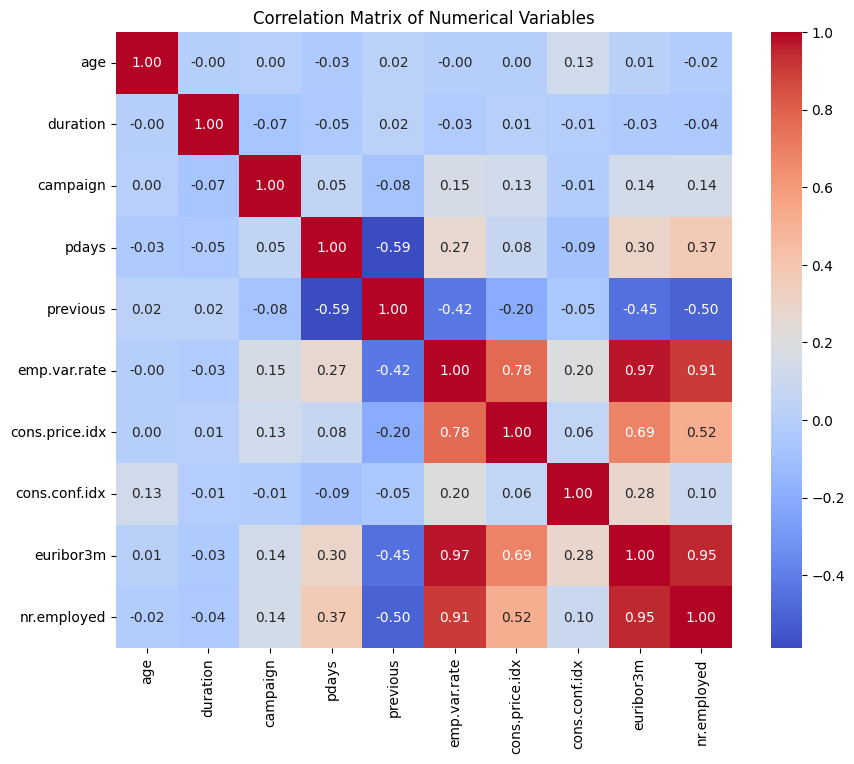

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation matrix
corr = df[numerical_cols].corr()

plt.figure(figsize=(10,8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True
)

plt.title("Correlation Matrix of Numerical Variables")
plt.show()

A correlation matrix was used to examine relationships among numerical predictors and identify potential multicollinearity.

Strong positive correlations were observed among the macroeconomic indicators, particularly between emp.var.rate and euribor3m (0.97), euribor3m and nr.employed (0.95), and emp.var.rate and nr.employed (0.91). These findings suggest that the economic indicators capture related aspects of the broader economic environment.

A moderately strong negative correlation was observed between pdays and previous (-0.59), indicating that customers with more previous interactions tend to have shorter intervals since their last contact.

Most remaining numerical variables exhibited relatively weak correlations, suggesting that they provide distinct information.

Although multicollinearity may affect coefficient interpretation in Logistic Regression, no variables were removed at this stage. This decision was made because tree-based methods are generally robust to correlated predictors and because subsequent model evaluation will determine the practical importance of each variable.

**Data Preparation**

*Investigation of pdays*

In [22]:

# Top pdays values
print("Top pdays values:\n")
print(df['pdays'].value_counts().head(10))

# Percentage of customers with pdays = 999
pct_999 = round((df['pdays'] == 999).mean() * 100, 2)

print(f"\nPercentage of observations with pdays = 999: {pct_999}%")

Top pdays values:

pdays
999    39661
3        439
6        412
4        118
9         64
2         61
7         60
12        58
10        52
5         46
Name: count, dtype: int64

Percentage of observations with pdays = 999: 96.32%


The variable pdays records the number of days since a customer was last contacted during a previous marketing campaign. Exploratory analysis revealed that 96.32% of observations contain the value 999.

According to the dataset documentation, a value of 999 indicates that the customer had not been previously contacted. Consequently, the variable does not represent a standard continuous measure and instead combines information about both previous contact status and the elapsed time since contact.

Given that the special value 999 carries meaningful information, the variable was retained without modification during the initial modelling process. This approach preserves potentially valuable predictive information while maintaining a straightforward and reproducible preprocessing pipeline.

However, future work could consider transforming the variable into separate features, such as a binary indicator of previous contact and the number of days since the last contact for previously contacted customers.

*Assessment of Multicollinearity*

In [23]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

# Numerical predictors only
X_num = df[
    ['age', 'duration', 'campaign', 'pdays', 'previous',
     'emp.var.rate', 'cons.price.idx',
     'cons.conf.idx', 'euribor3m', 'nr.employed']
]

# Calculate VIF
vif = pd.DataFrame()
vif["Variable"] = X_num.columns
vif["VIF"] = [
    variance_inflation_factor(X_num.values, i)
    for i in range(X_num.shape[1])
]

vif = vif.sort_values("VIF", ascending=False)

vif

,Variable,VIF
8,euribor3m,64.342128
5,emp.var.rate,33.066002
9,nr.employed,31.670063
6,cons.price.idx,6.337163
7,cons.conf.idx,2.649399
4,previous,1.796720
3,pdays,1.614864
2,campaign,1.038442
0,age,1.018794
1,duration,1.009459


Multicollinearity among numerical predictors was assessed using the Variance Inflation Factor (VIF).

The analysis revealed substantial multicollinearity among several macroeconomic variables. The highest VIF values were observed for euribor3m (64.34), emp.var.rate (33.07), and nr.employed (31.67), indicating that these variables contain highly overlapping information.

This finding is consistent with the correlation analysis, which demonstrated very strong positive relationships among the same variables.

Despite the presence of multicollinearity, no variables were removed at this stage. The primary objective of the project is predictive performance rather than coefficient interpretation, and tree-based algorithms such as Random Forest and XGBoost are generally robust to multicollinearity. The issue will, however, be considered when interpreting the results of the Logistic Regression model.

*Convert the Target Variable*

In [24]:
# Create a copy of the cleaned dataset
df_model = df.copy()

# Convert target variable
df_model['y'] = df_model['y'].map({
    'no': 0,
    'yes': 1
})

# Verify conversion
df_model['y'].value_counts()

,count
y,
0,36537
1,4639


The target variable (y) was converted from categorical labels to a binary numerical representation, where:

0 = Customer did not subscribe to a term deposit
1 = Customer subscribed to a term deposit
This transformation was required because machine learning algorithms operate on numerical target values. The conversion preserved the original class distribution, with 36,537 non-subscribers and 4,639 subscribers

*Create Both Feature Sets*

In [25]:
# Dataset with duration
df_with_duration = df_model.copy()

# Dataset without duration
df_without_duration = df_model.drop(columns=['duration'])

print("With duration:", df_with_duration.shape)
print("Without duration:", df_without_duration.shape)

With duration: (41176, 21)
Without duration: (41176, 20)


During exploratory analysis, the variable duration was identified as a potential source of data leakage because call duration is only known after a marketing call has been completed.

To assess the practical impact of this variable, two datasets were created:

A complete dataset containing all predictor variables, including duration.
A business-realistic dataset excluding duration.
The first dataset is expected to provide maximum predictive performance, while the second dataset reflects a realistic operational scenario in which customer subscription must be predicted before a call is made.

Comparing these two modelling approaches provides an additional robustness check and helps evaluate the practical applicability of the developed models.

*Encode Predictor Variables*

In [26]:

# Dataset with duration
df_with_duration_encoded = pd.get_dummies(
    df_with_duration,
    drop_first=True
)

# Dataset without duration
df_without_duration_encoded = pd.get_dummies(
    df_without_duration,
    drop_first=True
)

print("With duration:", df_with_duration_encoded.shape)
print("Without duration:", df_without_duration_encoded.shape)


With duration: (41176, 54)
Without duration: (41176, 53)


Machine learning algorithms require numerical input variables. Therefore, all categorical predictor variables were transformed using one-hot encoding.

One-hot encoding creates binary indicator variables for each category while preserving the original information contained within the categorical features. To avoid redundancy and reduce the risk of perfect multicollinearity, the first category of each variable was dropped (drop_first=True).

After encoding, the dataset containing the duration variable consisted of 54 variables, while the dataset excluding duration consisted of 53 variables.

*Feature and Target Separation*

In [27]:

# Dataset WITH duration
X_with = df_with_duration_encoded.drop('y', axis=1)
y_with = df_with_duration_encoded['y']

# Dataset WITHOUT duration
X_without = df_without_duration_encoded.drop('y', axis=1)
y_without = df_without_duration_encoded['y']

print("X_with shape:", X_with.shape)
print("y_with shape:", y_with.shape)

print("\nX_without shape:", X_without.shape)
print("y_without shape:", y_without.shape)


X_with shape: (41176, 53)
y_with shape: (41176,)

X_without shape: (41176, 52)
y_without shape: (41176,)


Following preprocessing and encoding, the target variable (y) was separated from the predictor variables.

The dataset containing duration consisted of 53 predictor variables, while the dataset excluding duration consisted of 52 predictor variables. Both datasets retained 41,176 observations.

This separation prepares the data for train-test splitting and subsequent model development.

*Train-Test Split*

In [28]:
from sklearn.model_selection import train_test_split

# ==========================================
# DATASET WITH DURATION
# ==========================================

X_train_with, X_test_with, y_train_with, y_test_with = train_test_split(
    X_with,
    y_with,
    test_size=0.30,
    stratify=y_with,
    random_state=42
)

# ==========================================
# DATASET WITHOUT DURATION
# ==========================================

X_train_without, X_test_without, y_train_without, y_test_without = train_test_split(
    X_without,
    y_without,
    test_size=0.30,
    stratify=y_without,
    random_state=42
)

print("WITH DURATION")
print("Training set:", X_train_with.shape)
print("Testing set :", X_test_with.shape)

print("\nWITHOUT DURATION")
print("Training set:", X_train_without.shape)
print("Testing set :", X_test_without.shape)

WITH DURATION
Training set: (28823, 53)
Testing set : (12353, 53)

WITHOUT DURATION
Training set: (28823, 52)
Testing set : (12353, 52)


The data were divided into training and testing subsets using a 70:30 split. The training set was used for model development while the testing set was reserved for final performance evaluation.

Because the target variable exhibited substantial class imbalance, stratified sampling was applied to ensure that both subsets maintained the original class proportions. This approach reduces sampling bias and provides a more reliable assessment of model performance.

A fixed random seed (random_state=42) was used to ensure that all results are reproducible.

*Majority-Class Baseline Model*

In [29]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Majority-class baseline
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train_without, y_train_without)

# Predictions
y_pred_baseline = baseline.predict(X_test_without)

# Metrics
print("Accuracy :", round(accuracy_score(y_test_without, y_pred_baseline), 4))
print("Precision:", round(precision_score(y_test_without, y_pred_baseline, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test_without, y_pred_baseline, zero_division=0), 4))
print("F1 Score :", round(f1_score(y_test_without, y_pred_baseline, zero_division=0), 4))

Accuracy : 0.8873
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0


A majority-class baseline model was established using a Dummy Classifier that always predicts the most frequent class (non-subscriber).

The baseline achieved an accuracy of 88.73%, which is identical to the proportion of non-subscribers in the dataset. However, the model recorded zero precision, zero recall, and an F1-score of zero because it never predicted any customer as a subscriber.

These findings demonstrate that accuracy is a misleading evaluation metric for this problem due to the substantial class imbalance. Although the baseline achieves high accuracy, it provides no practical value because it fails to identify any potential subscribers.

Consequently, subsequent model evaluation will place greater emphasis on Precision, Recall, F1-Score, and ROC-AUC, which better reflect the model's ability to identify customers likely to subscribe to a term deposit.

###2. Select and rank at-most 3 approaches and/or suitable for predicting the term-deposit subscription? Justify your selection and ranking with supporting evidence.

#Model Selection
Three classification algorithms were selected for comparison:

##Logistic Regression
Logistic Regression was selected as a baseline machine learning classifier because it is simple, computationally efficient, and highly interpretable. The model provides probability estimates and enables a clear understanding of the relationship between predictors and subscription outcomes.

##Random Forest
Random Forest was selected because it can capture non-linear relationships, is robust to outliers, and can automatically model interactions between variables. It also provides measures of feature importance.

##XGBoost
XGBoost was selected because it is a powerful gradient boosting algorithm that has demonstrated strong performance in many tabular-data classification problems. It can capture complex relationships, handle mixed data types, and often achieves state-of-the-art predictive accuracy.

**Logistic Regression**

*Step 1: Scale the Data*

In [30]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# =============================
# WITHOUT DURATION DATASET
# =============================

X_train_without_scaled = scaler.fit_transform(X_train_without)
X_test_without_scaled = scaler.transform(X_test_without)

print("Training shape:", X_train_without_scaled.shape)
print("Testing shape :", X_test_without_scaled.shape)

Training shape: (28823, 52)
Testing shape : (12353, 52)


Feature scaling was performed using standardization before fitting the Logistic Regression model. Standardization transforms each predictor to have a mean of zero and a standard deviation of one.

This step was necessary because Logistic Regression is sensitive to differences in variable scales. Standardization improves numerical stability and ensures that variables with larger magnitudes do not exert undue influence on the model estimation process.

Scaling was applied after the train-test split to prevent information leakage from the test set into the training process.

*Step 2: Fit Logistic Regression*

In [31]:
from sklearn.linear_model import LogisticRegression

# Logistic Regression Model
lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
lr.fit(X_train_without_scaled, y_train_without)

# Predictions
y_pred_lr = lr.predict(X_test_without_scaled)

# Predicted probabilities
y_prob_lr = lr.predict_proba(X_test_without_scaled)[:, 1]

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


The dataset was partitioned into training and testing subsets using a 70:30 ratio. The training dataset contained 28,823 observations (70%) and was used for model development, while the testing dataset contained 12,353 observations (30%) and was reserved for performance evaluation.

Stratified sampling was applied to preserve the original class distribution of the target variable in both subsets. This approach is particularly important because only 11.27% of customers subscribed to a term deposit.

A fixed random seed (random_state = 42) was used to ensure reproducibility of the results.

*evaluate its performance.*

In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("LOGISTIC REGRESSION RESULTS")
print("-" * 35)

print("Accuracy :", round(accuracy_score(y_test_without, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test_without, y_pred_lr), 4))
print("Recall   :", round(recall_score(y_test_without, y_pred_lr), 4))
print("F1 Score :", round(f1_score(y_test_without, y_pred_lr), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test_without, y_prob_lr), 4))

LOGISTIC REGRESSION RESULTS
-----------------------------------
Accuracy : 0.8991
Precision: 0.6615
Recall   : 0.2134
F1 Score : 0.3227
ROC-AUC  : 0.8038


A Logistic Regression model was trained using the dataset excluding the duration variable. The model achieved an accuracy of 89.91%, exceeding the majority-class baseline accuracy of 88.73%.

The model produced a precision score of 0.6615, indicating that approximately two-thirds of customers predicted as subscribers actually subscribed to a term deposit. However, the recall score was relatively low (0.2134), suggesting that many actual subscribers were not identified by the model.

The ROC-AUC score of 0.8038 indicates good discriminatory ability, demonstrating that the model can effectively distinguish between subscribers and non-subscribers across different classification thresholds.

Overall, Logistic Regression provides a strong and interpretable benchmark model. However, its low recall suggests that alternative modelling approaches may be necessary to identify a larger proportion of potential subscribers

*Logistic Regression Confusion Matrix*

In [33]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_without, y_pred_lr)

print(cm)

[[10809   152]
 [ 1095   297]]


The confusion matrix indicates that the Logistic Regression model correctly classified 10,809 non-subscribers and 297 subscribers.

Only 152 customers were incorrectly classified as subscribers (false positives), demonstrating that the model is relatively conservative when predicting positive outcomes. This behaviour contributes to the high precision score observed earlier.

However, the model failed to identify 1,095 actual subscribers (false negatives). Consequently, while the model is effective at limiting unnecessary marketing contacts, it misses a substantial proportion of potential subscribers.

From a business perspective, the model prioritizes precision over recall, reducing unnecessary calls but potentially foregoing valuable subscription opportunities.

*Overfitting Check*

In [34]:
from sklearn.metrics import roc_auc_score

# Training probabilities
y_train_prob_lr = lr.predict_proba(X_train_without_scaled)[:, 1]

# Training ROC-AUC
train_auc_lr = roc_auc_score(y_train_without, y_train_prob_lr)

# Test ROC-AUC
test_auc_lr = roc_auc_score(y_test_without, y_prob_lr)

print("Training ROC-AUC:", round(train_auc_lr, 4))
print("Testing ROC-AUC :", round(test_auc_lr, 4))
print("Difference      :", round(train_auc_lr - test_auc_lr, 4))

Training ROC-AUC: 0.7911
Testing ROC-AUC : 0.8038
Difference      : -0.0127


To assess model generalization, ROC-AUC scores were compared between the training and testing datasets.

The Logistic Regression model achieved a training ROC-AUC of 0.7911 and a testing ROC-AUC of 0.8038. The difference between the two scores was minimal (-0.0127), indicating that the model generalizes well to unseen observations.

These results suggest that Logistic Regression is not overfitting the training data and provides a stable benchmark for comparison with more complex machine learning algorithms.

*Cross-Validation Results for Logistic Regression*

In [35]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression

# Logistic Regression for CV
lr_cv = LogisticRegression(
    max_iter=1000,
    random_state=42
)

cv_scores = cross_val_score(
    lr_cv,
    X_train_without_scaled,
    y_train_without,
    cv=5,
    scoring='roc_auc'
)

print("Cross-Validation ROC-AUC Scores:")
print(cv_scores)

print("\nMean ROC-AUC:", round(cv_scores.mean(), 4))
print("Std ROC-AUC :", round(cv_scores.std(), 4))

Cross-Validation ROC-AUC Scores:
[0.77812244 0.78755756 0.78090413 0.80088052 0.78843141]

Mean ROC-AUC: 0.7872
Std ROC-AUC : 0.0079


Five-fold cross-validation was performed to evaluate the stability and robustness of the Logistic Regression model.

The model achieved a mean ROC-AUC score of 0.7872 with a standard deviation of 0.0079. The small variation across validation folds indicates that model performance is stable and not strongly dependent on a particular training sample.

Together with the train-test comparison, these results provide further evidence that the Logistic Regression model generalizes well and is not overfitting the training data.

#Random Forest

In [36]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest Model
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train model
rf.fit(X_train_without, y_train_without)

# Predictions
y_pred_rf = rf.predict(X_test_without)

# Predicted probabilities
y_prob_rf = rf.predict_proba(X_test_without)[:, 1]

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


*Random Forest Evaluation*

In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("RANDOM FOREST RESULTS")
print("-" * 35)

print("Accuracy :", round(accuracy_score(y_test_without, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test_without, y_pred_rf), 4))
print("Recall   :", round(recall_score(y_test_without, y_pred_rf), 4))
print("F1 Score :", round(f1_score(y_test_without, y_pred_rf), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test_without, y_prob_rf), 4))

RANDOM FOREST RESULTS
-----------------------------------
Accuracy : 0.8926
Precision: 0.5481
Recall   : 0.2658
F1 Score : 0.358
ROC-AUC  : 0.7787


The Random Forest model achieved an accuracy of 89.26%, a precision score of 0.5481, a recall score of 0.2658, an F1-score of 0.3580, and a ROC-AUC score of 0.7787.

Compared with Logistic Regression, Random Forest achieved higher recall and F1-score values, indicating an improved ability to identify actual subscribers. However, Logistic Regression achieved superior precision and ROC-AUC performance.

These findings suggest a trade-off between the two models. Random Forest identifies a greater proportion of potential subscribers, while Logistic Regression produces more reliable positive predictions and stronger overall discrimination performance.

*RANDOM FOREST: CONFUSION MATRIX,OVERFITTING CHECK & CROSS-VALIDATION*

In [38]:

from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.model_selection import cross_val_score
import pandas as pd

# -----------------------------
# 1. Confusion Matrix
# -----------------------------
cm_rf = confusion_matrix(y_test_without, y_pred_rf)

print("CONFUSION MATRIX")
print(cm_rf)

# -----------------------------
# 2. Overfitting Assessment
# -----------------------------
y_train_prob_rf = rf.predict_proba(X_train_without)[:, 1]

train_auc_rf = roc_auc_score(
    y_train_without,
    y_train_prob_rf
)

test_auc_rf = roc_auc_score(
    y_test_without,
    y_prob_rf
)

print("\nOVERFITTING ASSESSMENT")
print(f"Training ROC-AUC: {train_auc_rf:.4f}")
print(f"Testing ROC-AUC : {test_auc_rf:.4f}")
print(f"Difference      : {train_auc_rf - test_auc_rf:.4f}")

# -----------------------------
# 3. Cross Validation
# -----------------------------
cv_scores_rf = cross_val_score(
    RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    X_train_without,
    y_train_without,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

print("\nCROSS-VALIDATION ROC-AUC SCORES")
print(cv_scores_rf)

print(f"\nMean ROC-AUC: {cv_scores_rf.mean():.4f}")
print(f"Std ROC-AUC : {cv_scores_rf.std():.4f}")

CONFUSION MATRIX
[[10656   305]
 [ 1022   370]]

OVERFITTING ASSESSMENT
Training ROC-AUC: 0.9999
Testing ROC-AUC : 0.7787
Difference      : 0.2212

CROSS-VALIDATION ROC-AUC SCORES
[0.7616746  0.77015324 0.76989142 0.78233631 0.76715317]

Mean ROC-AUC: 0.7702
Std ROC-AUC : 0.0068


The Random Forest model achieved a recall score of 0.2658 and an F1-score of 0.3580, both of which exceeded the corresponding scores obtained by Logistic Regression. This indicates an improved ability to identify customers who subscribe to a term deposit.

However, the model displayed substantial overfitting. The training ROC-AUC score was 0.9999 compared with a testing ROC-AUC score of 0.7787, indicating a large decline in performance when applied to unseen data.

Five-fold cross-validation produced a mean ROC-AUC score of 0.7702, which was lower than the corresponding Logistic Regression score of 0.7872. These findings suggest that although Random Forest improves recall, its overall predictive performance and generalization ability are inferior to Logistic Regression under the current configuration.

The confusion matrix further revealed a trade-off between identifying additional subscribers and generating a larger number of unnecessary marketing contacts.

**XGBoost**

*Training *

In [39]:
from xgboost import XGBClassifier

# XGBoost model
xgb = XGBClassifier(
    eval_metric='logloss',
    random_state=42
)

# Train model
xgb.fit(X_train_without, y_train_without)

# Predictions
y_pred_xgb = xgb.predict(X_test_without)

# Predicted probabilities
y_prob_xgb = xgb.predict_proba(X_test_without)[:, 1]

print("XGBoost model trained successfully.")

XGBoost model trained successfully.


*Evaluation *

In [40]:


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
from sklearn.model_selection import cross_val_score

# -----------------------------
# 1. Performance Metrics
# -----------------------------
print("XGBOOST RESULTS")
print("-" * 35)

print("Accuracy :", round(accuracy_score(y_test_without, y_pred_xgb), 4))
print("Precision:", round(precision_score(y_test_without, y_pred_xgb), 4))
print("Recall   :", round(recall_score(y_test_without, y_pred_xgb), 4))
print("F1 Score :", round(f1_score(y_test_without, y_pred_xgb), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test_without, y_prob_xgb), 4))

# -----------------------------
# 2. Confusion Matrix
# -----------------------------
cm_xgb = confusion_matrix(y_test_without, y_pred_xgb)

print("\nCONFUSION MATRIX")
print(cm_xgb)

# -----------------------------
# 3. Overfitting Assessment
# -----------------------------
y_train_prob_xgb = xgb.predict_proba(X_train_without)[:, 1]

train_auc_xgb = roc_auc_score(
    y_train_without,
    y_train_prob_xgb
)

test_auc_xgb = roc_auc_score(
    y_test_without,
    y_prob_xgb
)

print("\nOVERFITTING ASSESSMENT")
print(f"Training ROC-AUC: {train_auc_xgb:.4f}")
print(f"Testing ROC-AUC : {test_auc_xgb:.4f}")
print(f"Difference      : {train_auc_xgb - test_auc_xgb:.4f}")

# -----------------------------
# 4. Cross Validation
# -----------------------------
xgb_cv = XGBClassifier(
    eval_metric='logloss',
    random_state=42
)

cv_scores_xgb = cross_val_score(
    xgb_cv,
    X_train_without,
    y_train_without,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

print("\nCROSS-VALIDATION ROC-AUC SCORES")
print(cv_scores_xgb)

print(f"\nMean ROC-AUC: {cv_scores_xgb.mean():.4f}")
print(f"Std ROC-AUC : {cv_scores_xgb.std():.4f}")

XGBOOST RESULTS
-----------------------------------
Accuracy : 0.8953
Precision: 0.5777
Recall   : 0.2644
F1 Score : 0.3627
ROC-AUC  : 0.7875

CONFUSION MATRIX
[[10692   269]
 [ 1024   368]]

OVERFITTING ASSESSMENT
Training ROC-AUC: 0.9111
Testing ROC-AUC : 0.7875
Difference      : 0.1237

CROSS-VALIDATION ROC-AUC SCORES
[0.76728994 0.78374915 0.77364824 0.78754351 0.77772029]

Mean ROC-AUC: 0.7780
Std ROC-AUC : 0.0072


Overall, XGBoost provided strong predictive performance and achieved the best balance between subscriber detection and prediction reliability. Although its overall ROC-AUC was slightly lower than Logistic Regression, it outperformed Random Forest and produced the highest F1-score among all evaluated models.

#RANKING

##Rank 1: Logistic Regression

Logistic Regression was ranked first because it achieved the highest ROC-AUC score (0.8038), the highest cross-validation ROC-AUC (0.7872), and the highest precision score (0.6615). The model also demonstrated excellent generalization with virtually no evidence of overfitting. In addition, Logistic Regression offers superior interpretability, making it easier for decision-makers to understand and justify predictions. Given the objective of identifying high-quality prospects for marketing campaigns while minimizing unnecessary calls, Logistic Regression provides the most reliable overall solution.

##Rank 2: XGBoost

XGBoost was ranked second because it achieved the highest F1-score (0.3627), demonstrating the best balance between precision and recall. The model identified substantially more subscribers than Logistic Regression while maintaining acceptable predictive reliability. Although some overfitting was observed, it generalized considerably better than Random Forest and delivered strong, consistent performance across validation folds.

##Rank 3: Random Forest

Random Forest was ranked third despite achieving the highest recall score. The model exhibited substantial overfitting, with an extremely high training ROC-AUC (0.9999) compared to its testing ROC-AUC (0.7787). Its cross-validation performance was also the weakest among the three models. Consequently, while Random Forest identified more potential subscribers, its overall predictive reliability and generalization ability were inferior to the other approaches.

##Conclusion for Question 2

The results indicate that all three machine learning models significantly outperformed the majority-class baseline. Logistic Regression achieved the strongest overall performance in terms of discrimination ability, precision, stability, and generalization, making it the preferred model for predicting customer subscription to term deposits. XGBoost provided the best balance between precision and recall and represents a strong alternative where identifying additional subscribers is prioritized. Random Forest demonstrated the weakest overall performance due to substantial overfitting despite achieving competitive recall.

Based on the combined evidence from predictive performance, cross-validation, and robustness assessment, Logistic Regression is recommended as the best-performing model for this bank marketing prediction task.

**Question 3: Recommend a Decision Threshold and Explain the Trade-off Between Unnecessary Calls and Missed Subscribers**

*Step 1: Evaluate Multiple Thresholds*

In [41]:


import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

results = []

for threshold in thresholds:

    y_pred_threshold = (y_prob_lr >= threshold).astype(int)

    precision = precision_score(y_test_without, y_pred_threshold)
    recall = recall_score(y_test_without, y_pred_threshold)
    f1 = f1_score(y_test_without, y_pred_threshold)

    results.append([
        threshold,
        round(precision,4),
        round(recall,4),
        round(f1,4)
    ])

threshold_results = pd.DataFrame(
    results,
    columns=[
        "Threshold",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

threshold_results

,Threshold,Precision,Recall,F1 Score
0,0.1,0.3242,0.6803,0.4391
1,0.2,0.4423,0.5668,0.4969
2,0.3,0.5043,0.4253,0.4614
3,0.4,0.5701,0.3010,0.3940
4,0.5,0.6615,0.2134,0.3227
5,0.6,0.7178,0.1681,0.2724
6,0.7,0.7512,0.1106,0.1929


The default classification threshold of 0.50 was evaluated against alternative thresholds ranging from 0.10 to 0.70. The results demonstrated a clear trade-off between precision and recall.

As the threshold increased, precision improved while recall declined. Higher thresholds reduced the number of unnecessary marketing contacts but increased the number of potential subscribers who were missed. Conversely, lower thresholds identified more subscribers but generated more false positives.

The highest F1-score (0.4969) was achieved at a threshold of 0.20, with a precision of 44.23% and a recall of 56.68%. Compared with the default threshold of 0.50, this threshold more than doubled the recall rate while maintaining acceptable precision.

Consequently, a threshold of 0.20 is recommended for future marketing campaigns. This threshold provides the most effective balance between minimizing unnecessary calls and maximizing the identification of potential subscribers. Given the relatively low cost of an additional marketing call compared with the potential revenue generated by a successful term-deposit subscription, the bank should prioritize identifying likely subscribers even at the expense of some additional false positives.

#Conclusion
This project developed and evaluated machine learning models to predict term-deposit subscription using the Bank Marketing dataset. Exploratory data analysis revealed a highly imbalanced target variable, significant relationships between subscription behaviour and previous campaign outcomes, contact methods, and economic indicators, as well as potential data leakage associated with the duration variable.

Three classification models were evaluated: Logistic Regression, Random Forest, and XGBoost. Logistic Regression achieved the strongest overall performance, producing the highest ROC-AUC (0.8038), highest precision (0.6615), strongest cross-validation performance, and no evidence of overfitting. XGBoost achieved the highest F1-score, while Random Forest demonstrated the strongest tendency to overfit.

Threshold analysis showed that the default classification threshold of 0.50 was not optimal for the marketing objective. A threshold of 0.20 achieved the highest F1-score and substantially improved subscriber detection while maintaining reasonable precision.

Overall, Logistic Regression with a decision threshold of 0.20 is recommended as the preferred approach for supporting customer selection in future marketing campaigns. This approach provides a practical balance between minimizing unnecessary calls and maximizing the identification of potential subscribers.